# Grid Pulse EV — Step 1: Synthetic EV Sessions & Uncontrolled Baseline

**Research:** Optimizing Public EV Charging Schedules for Renewable-Curtailment Absorption and Peak Reduction in Sri Lanka.

**WARNING:** This notebook uses illustrative, synthetic EV arrivals/energy/dwell durations. These are **not calibrated to Sri Lankan public chargers** and do not establish renewable curtailment or peak reduction. It builds the engineering baseline against which a future optimized schedule will be compared.

No original PUCSL/CEB data are modified; diagnostic outputs go under `results/ev_baseline/`.


In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts" / "ev_charging_baseline.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "ev_charging_baseline.py").is_file():
    raise FileNotFoundError("Open this notebook from the grid-pulse-ev-starter project (or its notebooks folder)")
sys.path.insert(0, str(ROOT / "scripts"))
from ev_charging_baseline import generate_synthetic_sessions, simulate_uncontrolled, run_experiment, TZ
print("Project root:", ROOT)


Project root: C:\Users\isuru\Documents\Projects\grid-pulse-ev-starter


## 1. Reproducible experiment settings

Try different seeds and session counts later as **sensitivity scenarios**, not claims about Sri Lanka. A seven-day period in April 2024 was chosen to allow an optional alignment with your existing 2024 grid dataset.

In [2]:
START_DATE = "2024-04-01"
DAYS = 7
SESSIONS_PER_DAY = 20
RANDOM_SEED = 42
OUTDIR = ROOT / "results" / "ev_baseline"
metrics = run_experiment(OUTDIR, START_DATE, DAYS, SESSIONS_PER_DAY, RANDOM_SEED)
print(json.dumps(metrics, indent=2))
print("Saved to:", OUTDIR)


{
  "data_status": "SYNTHETIC_UNCALIBRATED_SCENARIO",
  "charging_policy": "immediate_max_power_per_session_no_site_capacity_constraint",
  "interval_minutes": 15,
  "number_of_sessions": 140,
  "total_requested_kwh": 2561.87,
  "total_delivered_kwh": 2400.09,
  "total_unmet_kwh": 161.78,
  "fully_served_sessions": 121,
  "fully_served_fraction": 0.8643,
  "peak_incremental_site_kw": 65.2,
  "maximum_concurrent_connected": 12,
  "seed": 42,
  "start_date": "2024-04-01",
  "days": 7,
  "sessions_per_day": 20
}
Saved to: C:\Users\isuru\Documents\Projects\grid-pulse-ev-starter\results\ev_baseline


## 2. Check the generated sessions and delivered energy

`energy_request_kwh` is an assumed target, not ACN-Data `kWhDelivered` (which measures historical delivered electricity). A driver may leave with unmet demand.

In [3]:
sessions = pd.read_csv(OUTDIR / "synthetic_ev_sessions.csv")
outcomes = pd.read_csv(OUTDIR / "uncontrolled_session_outcomes.csv")
profile = pd.read_csv(OUTDIR / "uncontrolled_site_load_15min.csv")
display(sessions.head(8))
display(outcomes.head(8))
print("Energy conservation check (kWh):", round(profile.site_charging_kw.sum() * 0.25 - outcomes.delivered_kwh.sum(), 8))
assert abs(profile.site_charging_kw.sum() * 0.25 - outcomes.delivered_kwh.sum()) < 1e-5


,session_id,arrival_local,departure_local,energy_request_kwh,max_power_kw,data_origin
0,syn-01-001,2024-04-01T08:00:00+05:30,2024-04-01T14:45:00+05:30,17.41,11.0,synthetic_illustrative_not_calibrated
1,syn-01-002,2024-04-01T08:00:00+05:30,2024-04-01T14:15:00+05:30,8.45,11.0,synthetic_illustrative_not_calibrated
2,syn-01-003,2024-04-01T17:15:00+05:30,2024-04-02T00:00:00+05:30,26.44,7.2,synthetic_illustrative_not_calibrated
3,syn-01-004,2024-04-01T18:45:00+05:30,2024-04-01T23:30:00+05:30,15.64,11.0,synthetic_illustrative_not_calibrated
4,syn-01-005,2024-04-01T17:45:00+05:30,2024-04-01T23:45:00+05:30,27.39,7.2,synthetic_illustrative_not_calibrated
5,syn-01-006,2024-04-01T13:15:00+05:30,2024-04-01T16:30:00+05:30,20.42,3.6,synthetic_illustrative_not_calibrated
6,syn-01-007,2024-04-01T19:00:00+05:30,2024-04-02T02:00:00+05:30,22.42,7.2,synthetic_illustrative_not_calibrated
7,syn-01-008,2024-04-01T16:45:00+05:30,2024-04-01T20:45:00+05:30,31.24,11.0,synthetic_illustrative_not_calibrated


,session_id,arrival_local,departure_local,requested_kwh,delivered_kwh,unmet_kwh,fully_served,completion_local
0,syn-01-001,2024-04-01T08:00:00+05:30,2024-04-01T14:45:00+05:30,17.41,17.41,0.00,True,2024-04-01T09:45:00+05:30
1,syn-01-002,2024-04-01T08:00:00+05:30,2024-04-01T14:15:00+05:30,8.45,8.45,0.00,True,2024-04-01T09:00:00+05:30
2,syn-01-017,2024-04-01T10:15:00+05:30,2024-04-01T16:30:00+05:30,9.63,9.63,0.00,True,2024-04-01T11:45:00+05:30
3,syn-01-016,2024-04-01T13:00:00+05:30,2024-04-01T20:00:00+05:30,16.07,16.07,0.00,True,2024-04-01T15:15:00+05:30
4,syn-01-006,2024-04-01T13:15:00+05:30,2024-04-01T16:30:00+05:30,20.42,11.70,8.72,False,NaN
5,syn-01-013,2024-04-01T13:15:00+05:30,2024-04-01T16:00:00+05:30,18.37,18.37,0.00,True,2024-04-01T16:00:00+05:30
6,syn-01-019,2024-04-01T13:30:00+05:30,2024-04-01T19:45:00+05:30,26.30,26.30,0.00,True,2024-04-01T17:15:00+05:30
7,syn-01-010,2024-04-01T13:45:00+05:30,2024-04-01T16:00:00+05:30,10.01,10.01,0.00,True,2024-04-01T15:15:00+05:30


Energy conservation check (kWh): -0.0


## 3. Uncontrolled site charging power

Immediate charging at each plugged-in vehicle's power ceiling. This baseline assumes sufficient EVSEs and does **not** impose a shared site capacity; therefore it is not yet a site-feasible charging schedule.

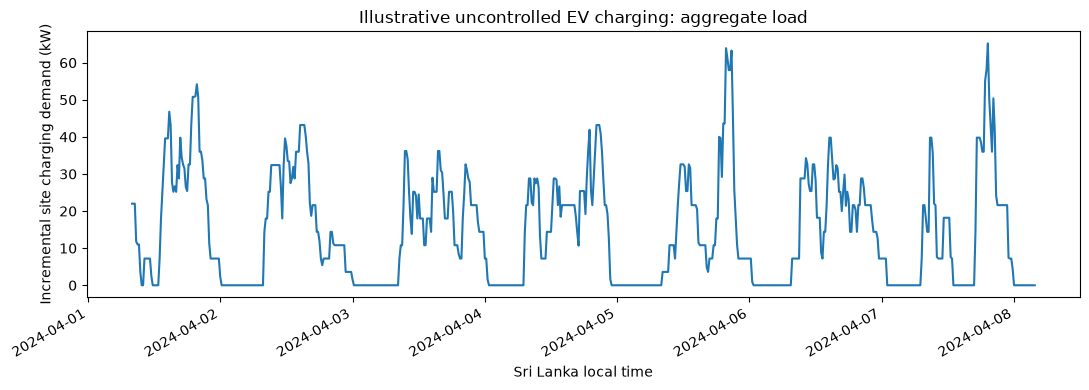

In [4]:
profile["t"] = pd.to_datetime(profile.interval_start_local, utc=True).dt.tz_convert(TZ)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(profile.t, profile.site_charging_kw)
ax.set_title("Illustrative uncontrolled EV charging: aggregate load")
ax.set_ylabel("Incremental site charging demand (kW)")
ax.set_xlabel("Sri Lanka local time")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


## 4. Session feasibility and unmet energy

Energy requests exceeding `max_power_kw × parking hours` may be physically infeasible even with immediate charging. An optimizer cannot satisfy those requests without changing the assumptions.

Fully served: 121 of 140
Unmet energy (kWh): 161.78


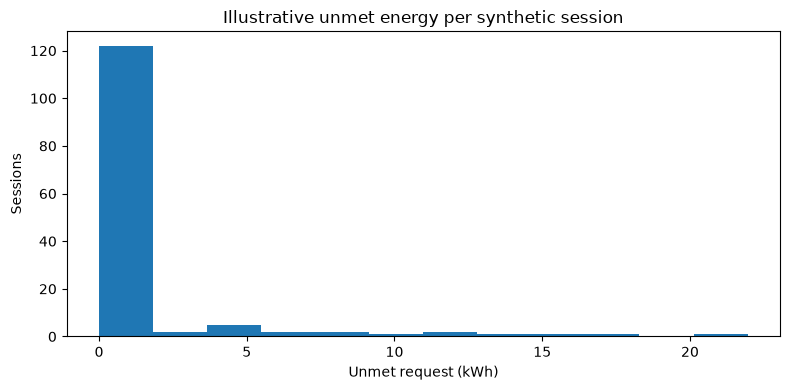

In [5]:
print("Fully served:", int(outcomes.fully_served.sum()), "of", len(outcomes))
print("Unmet energy (kWh):", round(outcomes.unmet_kwh.sum(), 2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(outcomes.unmet_kwh, bins=12)
ax.set_title("Illustrative unmet energy per synthetic session")
ax.set_xlabel("Unmet request (kWh)")
ax.set_ylabel("Sessions")
plt.tight_layout(); plt.show()


## 5. Optional: overlay incremental EV load on the 2024 PUCSL hourly dispatch **proxy**

Only attempt this where `hour_status == complete` and `is_system_event_day == False`. This is illustrative **additional** EV charging on top of PUCSL reported dispatch (which may already include some EV consumption). It is not verified national demand, observed charging growth, or an optimization result. Missing/flagged grid hours stay missing.

Quality-eligible hours displayed: 164 of 164


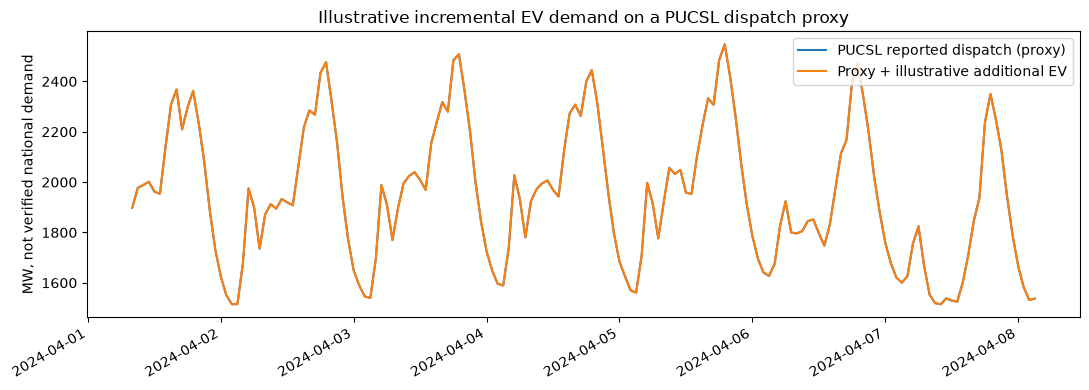

In [6]:
hourly_file = ROOT / "data" / "processed" / "grid" / "pucsl_2024_hourly_net_demand.csv"
if not hourly_file.exists():
    print("Optional grid overlay skipped: local hourly proxy file does not exist.")
else:
    grid = pd.read_csv(hourly_file)
    grid["t"] = pd.to_datetime(grid.hour_start_local, utc=True).dt.tz_convert(TZ)
    site = profile.set_index("t").site_charging_kw.resample("h").mean().rename("extra_ev_mw") / 1000.0
    grid = grid.merge(site, left_on="t", right_index=True, how="inner")
    is_event = grid.is_system_event_day.astype(str).str.lower().eq("true")
    eligible = grid.hour_status.eq("complete") & ~is_event
    graph = grid.loc[eligible].copy()
    graph["dispatch_plus_extra_ev_mw"] = graph.total_dispatch_reported_mw + graph.extra_ev_mw
    print("Quality-eligible hours displayed:", len(graph), "of", len(grid))
    if graph.empty:
        print("No eligible hours in selected period; no values were fabricated.")
    else:
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(graph.t, graph.total_dispatch_reported_mw, label="PUCSL reported dispatch (proxy)")
        ax.plot(graph.t, graph.dispatch_plus_extra_ev_mw, label="Proxy + illustrative additional EV")
        ax.set_title("Illustrative incremental EV demand on a PUCSL dispatch proxy")
        ax.set_ylabel("MW, not verified national demand")
        ax.legend()
        fig.autofmt_xdate(); plt.tight_layout(); plt.show()


## 6. Interpretation and next research task

**This stage proves a reproducible baseline implementation, not grid effectiveness.**

Next: obtain empirical EV-session records with provenance and access terms; test and document fields, especially requested versus delivered energy; add session-generator calibration and transferability scenarios. Then add charger/site constraints and compare optimized schedules against this uncontrolled baseline.

Official candidate source: [ACN-Data](https://ev.caltech.edu/dataset) (California campus/workplace; not representative of Sri Lankan public charging without further validation).